In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import LeaveOneOut, cross_val_score
from sklearn.metrics import mean_squared_error, r2_score

X = np.array([1,2,3,4,5,6,7,8,9,10]).reshape(-1,1)

y = np.array([42,48,55,59,66,70,78,81,89,91])

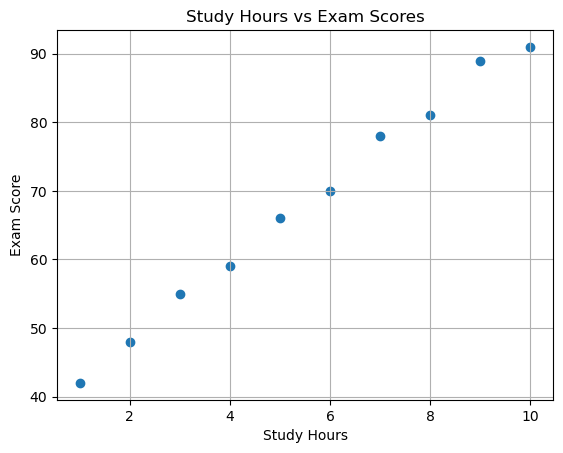

In [3]:
plt.scatter(X, y)

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Study Hours vs Exam Scores")

plt.grid()
plt.show()

In [4]:
model1 = LinearRegression()
model1.fit(X, y)

y_pred1 = model1.predict(X)

In [5]:
poly2 = PolynomialFeatures(degree=2)

X2 = poly2.fit_transform(X)

model2 = LinearRegression()
model2.fit(X2, y)

y_pred2 = model2.predict(X2)

In [6]:
poly3 = PolynomialFeatures(degree=3)

X3 = poly3.fit_transform(X)

model3 = LinearRegression()
model3.fit(X3, y)

y_pred3 = model3.predict(X3)

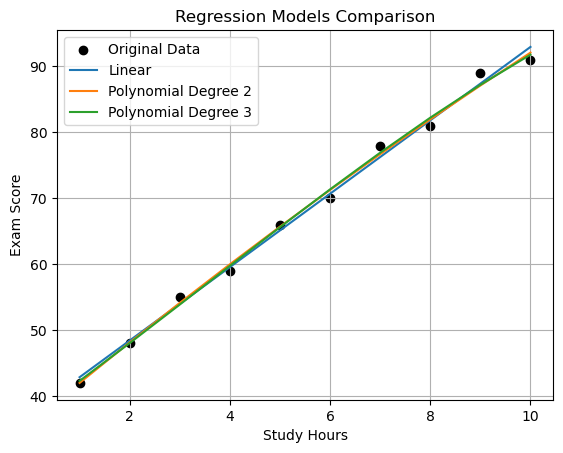

In [7]:
plt.scatter(X, y, color='black', label='Original Data')

plt.plot(X, y_pred1, label='Linear')
plt.plot(X, y_pred2, label='Polynomial Degree 2')
plt.plot(X, y_pred3, label='Polynomial Degree 3')

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.title("Regression Models Comparison")

plt.legend()
plt.grid()
plt.show()

In [8]:
models = [y_pred1, y_pred2, y_pred3]

names = ['Linear', 'Polynomial 2', 'Polynomial 3']

for name, pred in zip(names, models):

    rmse = np.sqrt(mean_squared_error(y, pred))
    r2 = r2_score(y, pred)

    print(name)
    print("RMSE:", rmse)
    print("R2:", r2)
    print("----------------")

Linear
RMSE: 1.1672293015617117
R2: 0.9947047135822448
----------------
Polynomial 2
RMSE: 1.043522589089187
R2: 0.9957676575306487
----------------
Polynomial 3
RMSE: 1.0211173549992452
R2: 0.9959474497544379
----------------


In [9]:
degrees = [1, 2, 3, 5, 9]

for degree in degrees:

    poly = PolynomialFeatures(degree=degree)
    X_poly = poly.fit_transform(X)

    model = LinearRegression()
    model.fit(X_poly, y)

    predictions = model.predict(X_poly)

    rmse = np.sqrt(mean_squared_error(y, predictions))

    print("Degree:", degree)
    print("Training RMSE:", rmse)
    print("----------------")

Degree: 1
Training RMSE: 1.167229301561712
----------------
Degree: 2
Training RMSE: 1.043522589089187
----------------
Degree: 3
Training RMSE: 1.0211173549992452
----------------
Degree: 5
Training RMSE: 0.8943229393309391
----------------
Degree: 9
Training RMSE: 7.52732717628022e-05
----------------


In [10]:
loo = LeaveOneOut()

for degree in degrees:

    model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree)),
        ('scaler', StandardScaler()),
        ('regression', LinearRegression())
    ])

    scores = cross_val_score(
        model, X, y,
        cv=loo,
        scoring='neg_mean_squared_error'
    )

    rmse = np.sqrt(-scores.mean())

    print("Degree:", degree)
    print("LOOCV RMSE:", rmse)
    print("----------------")

Degree: 1
LOOCV RMSE: 1.5486365728907225
----------------
Degree: 2
LOOCV RMSE: 1.5727732132789547
----------------
Degree: 3
LOOCV RMSE: 2.061987356600257
----------------
Degree: 5
LOOCV RMSE: 3.7069620484476244
----------------
Degree: 9
LOOCV RMSE: 222.16285382563433
----------------


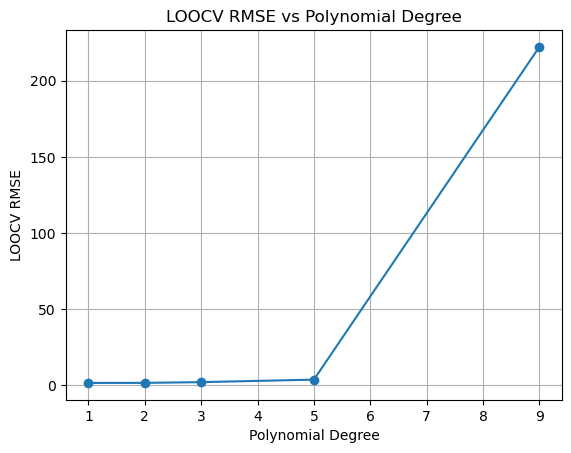

In [11]:
loocv_results = []

for degree in degrees:

    model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree)),
        ('scaler', StandardScaler()),
        ('regression', LinearRegression())
    ])

    scores = cross_val_score(
        model, X, y,
        cv=loo,
        scoring='neg_mean_squared_error'
    )

    loocv_results.append(np.sqrt(-scores.mean()))

plt.plot(degrees, loocv_results, marker='o')

plt.xlabel("Polynomial Degree")
plt.ylabel("LOOCV RMSE")
plt.title("LOOCV RMSE vs Polynomial Degree")

plt.grid()
plt.show()

In [12]:
degrees = [1, 3, 5]

for degree in degrees:

    model = Pipeline([
        ('poly', PolynomialFeatures(degree=degree)),
        ('scaler', StandardScaler()),
        ('regression', LinearRegression())
    ])

    scores = cross_val_score(
        model, X, y,
        cv=loo,
        scoring='neg_mean_squared_error'
    )

    rmse = np.sqrt(-scores.mean())

    print("Feature Degree:", degree)
    print("LOOCV RMSE:", rmse)
    print("----------------")

Feature Degree: 1
LOOCV RMSE: 1.5486365728907225
----------------
Feature Degree: 3
LOOCV RMSE: 2.061987356600257
----------------
Feature Degree: 5
LOOCV RMSE: 3.7069620484476244
----------------


In [13]:
alphas = [0.01, 0.1, 1, 10]

for alpha in alphas:

    model = Pipeline([
        ('poly', PolynomialFeatures(degree=5)),
        ('scaler', StandardScaler()),
        ('regression', Ridge(alpha=alpha))
    ])

    scores = cross_val_score(
        model, X, y,
        cv=loo,
        scoring='neg_mean_squared_error'
    )

    rmse = np.sqrt(-scores.mean())

    print("Ridge Alpha:", alpha)
    print("LOOCV RMSE:", rmse)

Ridge Alpha: 0.01
LOOCV RMSE: 2.1441547115499806
Ridge Alpha: 0.1
LOOCV RMSE: 1.8070583849916297
Ridge Alpha: 1
LOOCV RMSE: 3.573524776248508
Ridge Alpha: 10
LOOCV RMSE: 7.281994317191601


In [14]:
for alpha in alphas:

    model = Pipeline([
        ('poly', PolynomialFeatures(degree=5)),
        ('scaler', StandardScaler()),
        ('regression', Lasso(alpha=alpha, max_iter=100000))
    ])

    scores = cross_val_score(
        model, X, y,
        cv=loo,
        scoring='neg_mean_squared_error'
    )

    rmse = np.sqrt(-scores.mean())

    print("Lasso Alpha:", alpha)
    print("LOOCV RMSE:", rmse)

Lasso Alpha: 0.01
LOOCV RMSE: 1.765421054607824
Lasso Alpha: 0.1
LOOCV RMSE: 1.6222863931698095
Lasso Alpha: 1
LOOCV RMSE: 1.9186823482420445
Lasso Alpha: 10
LOOCV RMSE: 11.877318060265235


In [16]:
final_models = {

    'Linear Regression': Pipeline([
        ('poly', PolynomialFeatures(degree=1)),
        ('scaler', StandardScaler()),
        ('regression', LinearRegression())
    ]),

    'Polynomial Regression': Pipeline([
        ('poly', PolynomialFeatures(degree=3)),
        ('scaler', StandardScaler()),
        ('regression', LinearRegression())
    ]),

    'Ridge Regression': Pipeline([
        ('poly', PolynomialFeatures(degree=5)),
        ('scaler', StandardScaler()),
        ('regression', Ridge(alpha=0.1))
    ]),

    'Lasso Regression': Pipeline([
        ('poly', PolynomialFeatures(degree=5)),
        ('scaler', StandardScaler()),
        ('regression', Lasso(alpha=0.1, max_iter=100000))
    ])
}

In [17]:
for name, model in final_models.items():

    model.fit(X, y)

    predictions = model.predict(X)

    train_rmse = np.sqrt(mean_squared_error(y, predictions))

    r2 = r2_score(y, predictions)

    scores = cross_val_score(
        model, X, y,
        cv=loo,
        scoring='neg_mean_squared_error'
    )

    loocv_rmse = np.sqrt(-scores.mean())

    print("\n", name)
    print("Training RMSE:", train_rmse)
    print("R2:", r2)
    print("LOOCV RMSE:", loocv_rmse)


 Linear Regression
Training RMSE: 1.1672293015617126
R2: 0.9947047135822448
LOOCV RMSE: 1.5486365728907225

 Polynomial Regression
Training RMSE: 1.021117354999245
R2: 0.9959474497544379
LOOCV RMSE: 2.061987356600257

 Ridge Regression
Training RMSE: 1.0864675468092477
R2: 0.995412135216022
LOOCV RMSE: 1.8070583849916297

 Lasso Regression
Training RMSE: 1.0656143157363958
R2: 0.9955865604185847
LOOCV RMSE: 1.6222863931698095


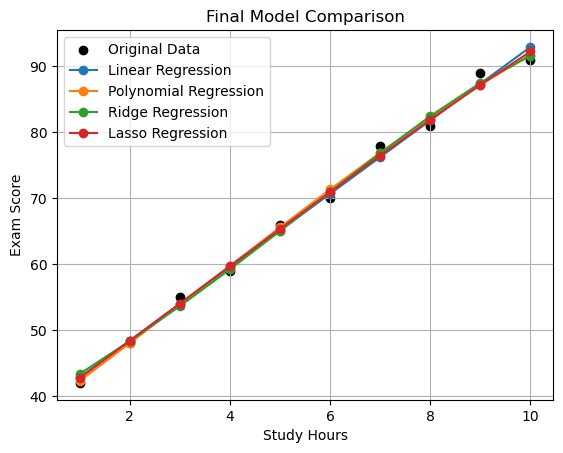

In [18]:
plt.scatter(X, y, color='black', label='Original Data')

for name, model in final_models.items():

    model.fit(X, y)

    plt.plot(X, model.predict(X), marker='o', label=name)

plt.xlabel("Study Hours")
plt.ylabel("Exam Score")

plt.title("Final Model Comparison")

plt.legend()
plt.grid()
plt.show()

In [19]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

In [20]:
additional_models = {

    'Decision Tree': DecisionTreeRegressor(random_state=42),

    'Random Forest': RandomForestRegressor(
        n_estimators=100,
        random_state=42
    ),

    'SVR': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVR())
    ]),

    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('model', KNeighborsRegressor(n_neighbors=3))
    ])
}

for name, model in additional_models.items():

    scores = cross_val_score(
        model, X, y,
        cv=loo,
        scoring='neg_mean_squared_error'
    )

    rmse = np.sqrt(-scores.mean())

    print(name)
    print("LOOCV RMSE:", rmse)

Decision Tree
LOOCV RMSE: 5.856620185738529
Random Forest
LOOCV RMSE: 4.584346191116025
SVR
LOOCV RMSE: 15.691165905703762
KNN
LOOCV RMSE: 6.176118881987655
